In [43]:
import geopandas as gpd
import numpy as np
from sklearn.cluster import DBSCAN
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

In [4]:
plots_with_indices = gpd.read_file("working/obsevation_plots_with_year_indices.gpkg")
natura_inventory = gpd.read_file("original/natura_elupaikPolygon.gpkg")

In [5]:
natura_inventory.dtypes

sys_id                 int32
versioon             float64
id                     int32
pohityyp                 str
pohityyp_p           float64
andmestik                str
kr_kood                  str
tyybid                   str
tyybid_p                 str
paal_97                  str
esinduslik               str
str_sail                 str
funkt_sail               str
taastatavs               str
lk_seisund               str
uldine_lk                str
markused                 str
inventisik               str
invent_kpv    datetime64[ms]
kaitst_ala               str
natura_ala               str
geometry            geometry
dtype: object

In [6]:
natura_inventory["pohityyp"].unique()

<StringArray>
['6280*',  '6430',  '6210',  '6510', '9080*', '6530*',  '6410',  '5130',
 '6270*', '91D0*',  '7230', '9010*',  '9070', '7110*',  '1620',  '6450',
 '7210*',  '2120',  '7140', '6210*',  '1310',  '2180', '9020*', '1630*',
  '7160',  '1160',  '1140',  '2320',  '1110',  '9060',  '9050',  '1170',
 '1150*',  '3110', '91E0*',  '3150',  '1220',  '7120', '3180*',  '3140',
  '1640',  '91F0',  '1230',  '1210',  '4030',  '3160', '2130*',  '7150',
 '9180*',  '3260', '2140*',  '2190',  '2110',  '8210', '8240*',  '8220',
  '2330', '7220*',  '3130',  '8310',  '1130']
Length: 61, dtype: str

In [8]:
codes = [
    "9010*", "9080", "91D0*", "9050",
    "9060", "91F0", "91E0*", "9020*", "2180", "9180*"
]

natura_inventory_forests = natura_inventory[natura_inventory["pohityyp"].isin(codes)
].copy()


In [9]:
len(natura_inventory_forests)

30538

In [10]:
natura_inventory_forests.head()

,sys_id,versioon,id,pohityyp,pohityyp_p,andmestik,kr_kood,tyybid,tyybid_p,paal_97,...,funkt_sail,taastatavs,lk_seisund,uldine_lk,markused,inventisik,invent_kpv,kaitst_ala,natura_ala,geometry
14,92212,1.747779e+12,148256581,91D0*,100.0,N,NaN,NaN,NaN,"1421,1511",...,III,III,C,A,"raiej�rgne, t��piline k�psev monotoonne m�nnik...","Anneli Palo,Indrek Tammek�nd",2023-08-01,Alam-Pedja looduskaitseala (KLO1000455),"Alam-Pedja linnuala (RAH0000123),Alam-Pedja lo...","MULTIPOLYGON (((623834.053 6486740.02, 623916...."
22,78650,1.752276e+12,-13363278,9010*,94.0,N,NaN,9080*;91D0*,5;1,1511,...,II,I,B,B,"tugev kuivendusm�ju, enamasti k�dusoo, ehkki l...",Indrek Sell,2019-08-20,Siiraku looduskaitseala (KLO1000573),"Kikepera linnuala (RAH0000118),Siiraku loodusa...","MULTIPOLYGON (((546158.403 6454430.196, 546226..."
24,87033,1.752276e+12,-20421956,9010*,90.0,N,NaN,9080*,10,1142,...,II,NaN,B,C,"Paiguti vanu sanitaarraiek�nde, kuid valdavalt...",Indrek Hiiesalu,2022-11-07,"Metsaelupaikade looduskaitseala,Metsaelupaikad...","Otep�� linnuala (RAH0000103),Otep�� loodusala ...","MULTIPOLYGON (((641024.991 6439567.528, 641044..."
29,62059,1.747779e+12,-15879249,9010*,100.0,N,NaN,NaN,NaN,1141,...,II,I,B,C,"65Hb20Ks10Ku5M�, vanus 75 a. vanemate kaskede ...",Raimo Pajula,2012-01-01,"Parika looduskaitseala (KLO1000190),Parika loo...","Parika linnuala (RAH0000081),Parika loodusala ...","MULTIPOLYGON (((601195.599 6489381.33, 601206...."
40,70918,1.738362e+12,8718468,9010*,100.0,N,NaN,NaN,NaN,1321,...,II,NaN,B,B,NaN,Toomas Tulev,2010-11-01,Lahemaa rahvuspark (KLO1000511),"Lahemaa linnuala (RAH0000089),Lahemaa loodusal...","MULTIPOLYGON (((625357.693 6606050.724, 625375..."


In [11]:
natura_inventory_forests["sys_id"].nunique()

30538

In [13]:
natura_inventory_forests.crs

<Projected CRS: EPSG:3301>
Name: Estonian Coordinate System of 1997
Axis Info [cartesian]:
- X[north]: Northing (metre)
- Y[east]: Easting (metre)
Area of Use:
- name: Estonia - onshore and offshore.
- bounds: (20.37, 57.52, 28.2, 60.0)
Coordinate Operation:
- name: Estonian National Grid
- method: Lambert Conic Conformal (2SP)
Datum: Estonia 1997
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [23]:
len(plots_with_indices)

1553

In [26]:
natura_inventory_forests["invent_kpv"] = pd.to_datetime(
    natura_inventory_forests["invent_kpv"], errors="coerce"
)

In [27]:
len(natura_inventory_forests)

30538

In [28]:
natura_inventory_forests.dtypes

sys_id                 int32
versioon             float64
id                     int32
pohityyp                 str
pohityyp_p           float64
andmestik                str
kr_kood                  str
tyybid                   str
tyybid_p                 str
paal_97                  str
esinduslik               str
str_sail                 str
funkt_sail               str
taastatavs               str
lk_seisund               str
uldine_lk                str
markused                 str
inventisik               str
invent_kpv    datetime64[ms]
kaitst_ala               str
natura_ala               str
geometry            geometry
dtype: object

In [14]:
plots_joined_inventory = gpd.sjoin(plots_with_indices, natura_inventory_forests[["sys_id", "pohityyp", "invent_kpv", "geometry"]], how="left", predicate="intersects")

In [15]:
plots_joined_inventory.dtypes

Proovi / vaatluse kood                                 str
Sisestatud x L-EST97                                   str
Sisestatud y L-EST97                                   str
Seireaja algus                                         str
Elupaiga esinduslikkus                                 str
Elupaiga funktsioonide säilimine                       str
Elupaiga üldine looduskaitseline väärtus               str
Elupaigatüüp (LD)                                      str
Kasvukohatüüp (Paal 1997)                              str
Koosluse struktuuri säilimine                          str
x                                                  float64
y                                                  float64
habitat                                                str
survey_date                                 datetime64[ms]
source                                                 str
habitat_code                                           str
plot_id                                              int

In [29]:
plots_joined_inventory_cleaned = (plots_joined_inventory.sort_values("invent_kpv", na_position="first").loc[lambda df: ~df.index.duplicated(keep="last")].copy())

In [31]:
print("Original plots:", len(plots_with_indices))
print("Joined plots:", len(plots_joined_inventory))
print("Cleaned joined plots:", len(plots_joined_inventory_cleaned))

Original plots: 1553
Joined plots: 1667
Cleaned joined plots: 1553


In [37]:
plots_grouped = plots_joined_inventory_cleaned.copy()
centres = plots_grouped.geometry.centroid
coords = np.column_stack([centres.x, centres.y])

plots_grouped["spatial_group"] = DBSCAN(eps=1000,min_samples=1).fit_predict(coords)


In [38]:
print("Total plots:", len(plots_grouped))
print("Spatial groups:", plots_grouped["spatial_group"].nunique())
print(plots_grouped["spatial_group"].value_counts())

Total plots: 1553
Spatial groups: 814
spatial_group
6      112
59      27
7       22
9       13
565     13
      ... 
807      1
808      1
809      1
811      1
813      1
Name: count, Length: 814, dtype: int64


In [39]:
plots_grouped.dtypes

Proovi / vaatluse kood                                 str
Sisestatud x L-EST97                                   str
Sisestatud y L-EST97                                   str
Seireaja algus                                         str
Elupaiga esinduslikkus                                 str
Elupaiga funktsioonide säilimine                       str
Elupaiga üldine looduskaitseline väärtus               str
Elupaigatüüp (LD)                                      str
Kasvukohatüüp (Paal 1997)                              str
Koosluse struktuuri säilimine                          str
x                                                  float64
y                                                  float64
habitat                                                str
survey_date                                 datetime64[ms]
source                                                 str
habitat_code                                           str
plot_id                                              int

In [40]:
plots_grouped["available_remote_sensing_year"].value_counts()

available_remote_sensing_year
2025    239
2020    227
2022    225
2023    187
2017    159
2024    159
2019    132
2021    127
2018     98
Name: count, dtype: int64

In [41]:
plots_grouped["habitat_code"].value_counts()

habitat_code
9010*    298
9080     178
0        168
91D0*    151
9050     128
9060     116
91F0     114
91E0*    113
9020*    102
2180      98
9180*     83
Name: count, dtype: int64

In [42]:
len(plots_grouped)

1553

In [44]:
plots_grouped_inventory_modified = plots_grouped.copy().reset_index(drop=True)

In [45]:
# Each DBSCAN spatial group initially belongs to itself
group_parent = {spatial_group: spatial_group for spatial_group in plots_grouped_inventory_modified["spatial_group"].unique()}


# Find the final group that a DBSCAN spatial group belongs to
def find_final_group(spatial_group):
    while group_parent[spatial_group] != spatial_group:
        spatial_group = group_parent[spatial_group]

    return spatial_group


# Connect two DBSCAN groups if they share an inventory polygon
def connect_spatial_groups(first_group, second_group):
    first_root = find_final_group(first_group)
    second_root = find_final_group(second_group)

    group_parent[first_root] = second_root


# Check each inventory polygon (sys_id)
for polygon_id, polygon_plots in plots_grouped_inventory_modified.dropna(
    subset=["sys_id"]).groupby("sys_id"):

    # Find all DBSCAN groups containing plots linked to this polygon
    spatial_groups = polygon_plots["spatial_group"].unique()

    # If the polygon contains plots from different DBSCAN groups,
    # connect those groups so they cannot be separated in train/test
    for spatial_group in spatial_groups[1:]:
        connect_spatial_groups(spatial_groups[0], spatial_group)


# Give all connected DBSCAN groups the same final group ID
plots_grouped_inventory_modified["group_id"] = pd.factorize(plots_grouped_inventory_modified["spatial_group"].map(find_final_group))[0]


# Check how many groups were merged
print("Original DBSCAN groups:", plots_grouped_inventory_modified["spatial_group"].nunique())

print("Final groups:", plots_grouped_inventory_modified["group_id"].nunique())

Original DBSCAN groups: 814
Final groups: 806


In [46]:
# Variables to balance
balance_cols = ["habitat_code", "available_remote_sensing_year"]

# Treat missing values as their own category for balancing
labels = plots_grouped_inventory_modified[balance_cols].astype("string").fillna("missing")

splitter = GroupShuffleSplit(n_splits=3000, test_size=0.2,random_state=42)

best_score = float("inf")
best_split = None

for train_idx, test_idx in splitter.split(plots_grouped_inventory_modified, groups=plots_grouped_inventory_modified["group_id"]):

    # Penalise deviation from 20% test observations
    score = 3 * abs(len(test_idx) / len(plots_grouped_inventory_modified) - 0.2)

    # Compare habitat and year distributions
    for col in balance_cols:
        overall = labels[col].value_counts(normalize=True)
        train = labels.iloc[train_idx][col].value_counts(normalize=True)
        test = labels.iloc[test_idx][col].value_counts(normalize=True)

        score += (
            (train.reindex(overall.index, fill_value=0) - overall).abs().sum()
            + (test.reindex(overall.index, fill_value=0) - overall).abs().sum()
        )

    if score < best_score:
        best_score = score
        best_split = (train_idx, test_idx)

# Assign train/test labels
train_idx, test_idx = best_split

plots_grouped_inventory_modified["split"] = "train"
plots_grouped_inventory_modified.loc[test_idx, "split"] = "test"

print(plots_grouped_inventory_modified["split"].value_counts())

split
train    1237
test      316
Name: count, dtype: int64


In [47]:
plots_grouped_inventory_modified.groupby("split")["available_remote_sensing_year"].value_counts()

split  available_remote_sensing_year
test   2025                              55
       2020                              48
       2022                              44
       2023                              36
       2024                              34
       2017                              33
       2019                              26
       2018                              20
       2021                              20
train  2025                             184
       2022                             181
       2020                             179
       2023                             151
       2017                             126
       2024                             125
       2021                             107
       2019                             106
       2018                              78
Name: count, dtype: int64

In [ ]:
pd.crosstab(plots_grouped_inventory_modified["available_remote_sensing_year"], plots_grouped_inventory_modified["split"], normalize="columns").mul(100).round(2)

split,test,train
available_remote_sensing_year,,
2017,10.44,10.19
2018,6.33,6.31
2019,8.23,8.57
2020,15.19,14.47
2021,6.33,8.65
2022,13.92,14.63
2023,11.39,12.21
2024,10.76,10.11
2025,17.41,14.87


In [49]:
plots_grouped_inventory_modified["available_remote_sensing_year"].value_counts(normalize=True).sort_index().mul(100).round(2)

available_remote_sensing_year
2017    10.24
2018     6.31
2019     8.50
2020    14.62
2021     8.18
2022    14.49
2023    12.04
2024    10.24
2025    15.39
Name: proportion, dtype: float64

In [50]:
pd.crosstab(plots_grouped_inventory_modified["habitat_code"], plots_grouped_inventory_modified["split"], normalize="columns").mul(100).round(2)

split,test,train
habitat_code,,
0,10.83,10.85
2180,7.32,6.07
9010*,19.11,19.27
9020*,5.73,6.80
9050,8.60,8.18
9060,9.55,6.96
9080,12.42,11.26
9180*,3.50,5.83
91D0*,9.55,9.80


In [53]:
plots_grouped_inventory_modified["habitat_code"].value_counts(normalize=True).sort_index().mul(100).round(2)

habitat_code
0        10.85
2180      6.33
9010*    19.24
9020*     6.58
9050      8.26
9060      7.49
9080     11.49
9180*     5.36
91D0*     9.75
91E0*     7.30
91F0      7.36
Name: proportion, dtype: float64

In [52]:
plots_grouped_inventory_modified.groupby("split")["habitat_code"].value_counts()

split  habitat_code
test   9010*            60
       9080             39
       0                34
       9060             30
       91D0*            30
       9050             27
       91F0             25
       2180             23
       9020*            18
       91E0*            17
       9180*            11
train  9010*           238
       9080            139
       0               134
       91D0*           121
       9050            101
       91E0*            96
       91F0             89
       9060             86
       9020*            84
       2180             75
       9180*            72
Name: count, dtype: int64

In [ ]:
# Every final spatial group belongs to exactly one split
assert plots_grouped_inventory_modified.groupby("group_id")["split"].nunique().max() == 1

# Every matched inventory polygon belongs to exactly one split
assert (plots_grouped_inventory_modified.dropna(subset=["sys_id"]).groupby("sys_id")["split"].nunique().max() == 1)

print("No group or inventory polygon leakage detected.")

No group or inventory polygon leakage detected.


In [55]:
plots_grouped_inventory_modified.dtypes

Proovi / vaatluse kood                                 str
Sisestatud x L-EST97                                   str
Sisestatud y L-EST97                                   str
Seireaja algus                                         str
Elupaiga esinduslikkus                                 str
Elupaiga funktsioonide säilimine                       str
Elupaiga üldine looduskaitseline väärtus               str
Elupaigatüüp (LD)                                      str
Kasvukohatüüp (Paal 1997)                              str
Koosluse struktuuri säilimine                          str
x                                                  float64
y                                                  float64
habitat                                                str
survey_date                                 datetime64[ms]
source                                                 str
habitat_code                                           str
plot_id                                              int

In [56]:
plots_grouped_inventory_modified.to_file("working/obsevation_plots_with_year_indices_split.gpkg", layer="obsevation_plots_with_year_indices_split", driver="GPKG")

In [57]:
plots_grouped_inventory_modified.crs


<Projected CRS: EPSG:3301>
Name: Estonian Coordinate System of 1997
Axis Info [cartesian]:
- X[north]: Northing (metre)
- Y[east]: Easting (metre)
Area of Use:
- name: Estonia - onshore and offshore.
- bounds: (20.37, 57.52, 28.2, 60.0)
Coordinate Operation:
- name: Estonian National Grid
- method: Lambert Conic Conformal (2SP)
Datum: Estonia 1997
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [58]:
plots_grouped_inventory_modified_centroids = plots_grouped_inventory_modified.copy()
plots_grouped_inventory_modified_centroids["geometry"] = plots_grouped_inventory_modified_centroids.geometry.centroid

In [59]:
plots_grouped_inventory_modified_centroids.to_file("working/obsevation_plots_with_year_indices_split_centroids.gpkg", layer="obsevation_plots_with_year_indices_split_centroids", driver="GPKG")

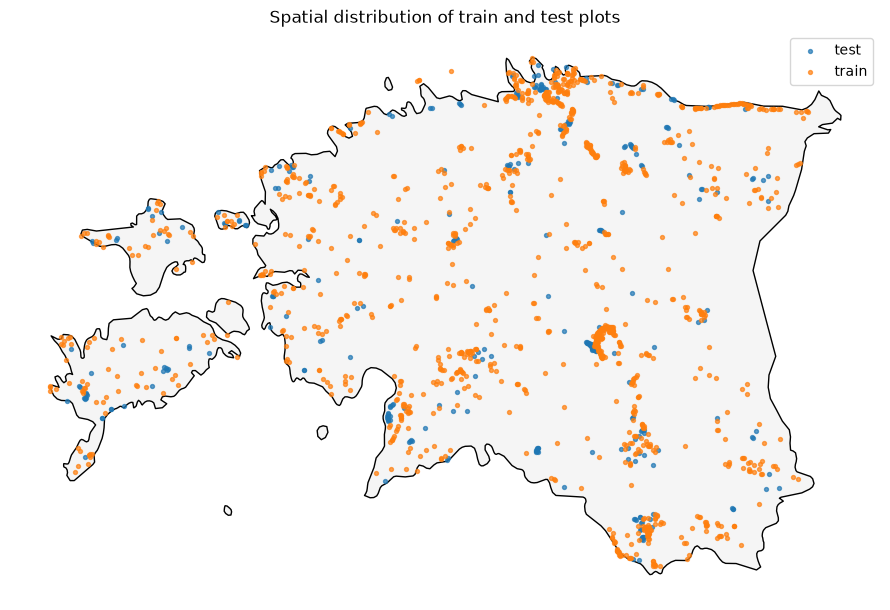

In [62]:
import matplotlib.pyplot as plt

estonia = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_countries.zip"
)
estonia = estonia[estonia["ADMIN"] == "Estonia"].to_crs(3301)

# Plot
fig, ax = plt.subplots(figsize=(9, 10))

estonia.plot(ax=ax, color="whitesmoke", edgecolor="black")

plots_grouped_inventory_modified_centroids.plot(
    ax=ax,
    column="split",
    categorical=True,
    legend=True,
    markersize=8,
    alpha=0.7
)

ax.set_title("Spatial distribution of train and test plots")
ax.set_axis_off()

plt.tight_layout()
plt.show()